# Khám phá dữ liệu WESAD — cửa sổ 60 giây, bước trượt 60 giây

**Phạm vi báo cáo hiện tại:** bảng thống kê tín hiệu ngực ECG, EDA và Resp;
cửa sổ 60 giây, bước trượt 60 giây, chỉ giữ cửa sổ đồng nhất nhãn
(`homogeneous`). Mỗi dòng là một cửa sổ; 21 đặc trưng là mean, std, min,
max, RMS, IQR và range của ba kênh. Đây chưa phải bộ đặc trưng sinh lý
HRV/SCR hoặc bộ cảm biến kết hợp.




## 1. Thiết lập đường dẫn và phạm vi


In [39]:
from pathlib import Path
import hashlib
import json
import warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Chỉ sửa biến này nếu notebook không tìm được gốc dự án.
PROJECT_ROOT_OVERRIDE = Path.cwd()  
if PROJECT_ROOT_OVERRIDE:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    candidates += [p / 'wesad-stress-detection' for p in list(candidates)]
    PROJECT_ROOT = next((p for p in candidates if (p / 'configs/features_chest.yaml').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Không tìm thấy gốc dự án. Hãy sửa PROJECT_ROOT_OVERRIDE ở trên.')

FEATURE_DIR = PROJECT_ROOT / '../data/features/chest_60s_step60_raw_stats_v1'
FEATURE_PATH = FEATURE_DIR / 'all_subjects.csv'
TABLE_DIR = PROJECT_ROOT / 'reports/tables/eda_step60'
FIG_DIR = PROJECT_ROOT / 'reports/figures/eda_step60'
for folder in (TABLE_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
EXPECTED_SUBJECTS = [f'S{i}' for i in [2,3,4,5,6,7,8,9,10,11,13,14,15,16,17]]
LABEL_NAMES = {1:'Baseline', 2:'Stress', 3:'Amusement'}
COLORS = ['#4c78a8', '#e45756', '#72b7b2']
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})

def save_table(frame, name, index=False):
    frame.to_csv(TABLE_DIR / name, index=index, encoding='utf-8-sig')

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)



## 2. Nạp dữ liệu và xác minh phiên bản
Notebook kiểm tra các cột, nhãn, khóa, thời gian và lưới bước 60 giây.
Khoảng cách giữa hai cửa sổ được giữ có thể là 120, 180,... giây vì cửa sổ
trung gian bị loại; điều đó không có nghĩa bước trượt đã thay đổi.
Nếu có `config.json` do extractor sinh ra, dùng nó đối chiếu cấu hình của bảng.
Nếu thiếu metadata này, chỉ có thể kiểm tra dấu hiệu từ bảng và ghi nhận hạn chế.


In [40]:
if not FEATURE_PATH.is_file():
    raise FileNotFoundError(f'Chưa có {FEATURE_PATH}. Chạy extractor 60/60 theo hướng dẫn đầu notebook.')
df = pd.read_csv(FEATURE_PATH, dtype={'subject_id':str, 'window_id':str})
if df.empty:
    raise ValueError('Bảng feature rỗng.')
required = ['subject_id','window_id','start_s','end_s','label_original','quality_flag']
feature_cols = [f'{sensor}_{stat}' for sensor in ['ecg','eda','resp']
                for stat in ['mean','std','min','max','rms','iqr','range']]
missing_cols = sorted(set(required + feature_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f'Thiếu cột: {missing_cols}. Hãy kiểm tra phiên bản feature.')
if df[required].isna().any().any():
    raise ValueError('Metadata bắt buộc bị thiếu; cần kiểm tra nguồn dữ liệu trước.')
for col in feature_cols + ['start_s','end_s','label_original']:
    df[col] = pd.to_numeric(df[col], errors='raise')
if not df.label_original.isin([1,2,3]).all():
    raise ValueError('Có nhãn ngoài 1/2/3, không tự ánh xạ thành non-stress.')
if not np.isfinite(df[['start_s','end_s']].to_numpy()).all():
    raise ValueError('Thời gian cửa sổ không hữu hạn.')
if (df.start_s < 0).any() or not np.isclose(df.end_s - df.start_s, 60, atol=1e-6, rtol=0).all():
    raise ValueError('Thời gian không hợp lệ hoặc có cửa sổ không dài 60 giây.')
if not np.isclose(df.start_s / 60, np.round(df.start_s / 60), atol=1e-6, rtol=0).all():
    raise ValueError('Có cửa sổ ngoài lưới 60 giây. Không dùng bộ 5 giây trong notebook này.')
ordered = df.sort_values(['subject_id','start_s'])
gaps = ordered.groupby('subject_id').start_s.diff().dropna()
if (gaps < 60 - 1e-6).any():
    raise ValueError('Có thời điểm trùng hoặc cửa sổ chồng lấn trong cùng subject.')

processing = None
if (FEATURE_DIR / 'config.json').is_file():
    snapshot = json.loads((FEATURE_DIR / 'config.json').read_text(encoding='utf-8'))
    processing = snapshot.get('processing', snapshot)
    for key, expected in {'window_seconds':60, 'step_seconds':60, 'label_rule':'homogeneous'}.items():
        if processing.get(key) != expected:
            raise ValueError(f'config.json: {key}={processing.get(key)!r}, cần {expected!r}.')
    print('Đã đối chiếu config.json: 60/60, homogeneous.')
else:
    warnings.warn('Thiếu config.json: lưới thời gian phù hợp 60 giây nhưng chưa xác minh được quy tắc nhãn từ bảng.')
subject_order = sorted(df.subject_id.unique(), key=lambda s: (int(s[1:]) if s[1:].isdigit() else 999, s))
missing_subjects = sorted(set(EXPECTED_SUBJECTS) - set(subject_order))
extra_subjects = sorted(set(subject_order) - set(EXPECTED_SUBJECTS))
if missing_subjects or extra_subjects:
    warnings.warn(f'Phạm vi subject khác 15 người dự kiến. Thiếu: {missing_subjects}; ngoài danh sách: {extra_subjects}')
print(f'{len(df):,} cửa sổ | {len(subject_order)} người | {len(feature_cols)} đặc trưng')
display(df.head())
df.info()




513 cửa sổ | 15 người | 21 đặc trưng


C:\Users\thanh\AppData\Local\Temp\ipykernel_14228\2325054420.py:38: UserWarning: Thiếu config.json: lưới thời gian phù hợp 60 giây nhưng chưa xác minh được quy tắc nhãn từ bảng.
  warnings.warn('Thiếu config.json: lưới thời gian phù hợp 60 giây nhưng chưa xác minh được quy tắc nhãn từ bảng.')


,subject_id,window_id,start_s,end_s,label_original,quality_flag,ecg_mean,ecg_std,ecg_min,ecg_max,...,eda_rms,eda_iqr,eda_range,resp_mean,resp_std,resp_min,resp_max,resp_rms,resp_iqr,resp_range
0,S2,S2_252000,360.0,420.0,1,finite_only_not_physiological_QA,0.000986,0.153720,-0.302902,0.862701,...,4.193222,0.410843,0.899887,0.061072,1.595619,-3.147888,3.730774,1.596787,2.864456,6.878662
1,S2,S2_294000,420.0,480.0,1,finite_only_not_physiological_QA,0.001455,0.182025,-1.499405,1.415726,...,3.551126,0.291443,0.663757,0.033488,1.885184,-6.646729,5.216980,1.885482,3.097916,11.863708
2,S2,S2_336000,480.0,540.0,1,finite_only_not_physiological_QA,0.001022,0.146379,-0.404984,0.776138,...,3.087097,0.274277,0.628281,0.073635,1.537771,-2.944946,4.554749,1.539533,2.726746,7.499695
3,S2,S2_378000,540.0,600.0,1,finite_only_not_physiological_QA,0.001122,0.144752,-0.272415,0.778793,...,2.625256,0.185108,0.689316,0.062645,1.441556,-3.240967,3.205872,1.442916,2.655029,6.446838
4,S2,S2_420000,600.0,660.0,1,finite_only_not_physiological_QA,0.001076,0.143769,-0.280563,0.806442,...,2.307896,0.134277,0.423813,0.038453,1.469767,-2.873230,3.224182,1.470270,2.658081,6.097412


<class 'pandas.DataFrame'>
RangeIndex: 513 entries, 0 to 512
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   subject_id      513 non-null    str    
 1   window_id       513 non-null    str    
 2   start_s         513 non-null    float64
 3   end_s           513 non-null    float64
 4   label_original  513 non-null    int64  
 5   quality_flag    513 non-null    str    
 6   ecg_mean        513 non-null    float64
 7   ecg_std         513 non-null    float64
 8   ecg_min         513 non-null    float64
 9   ecg_max         513 non-null    float64
 10  ecg_rms         513 non-null    float64
 11  ecg_iqr         513 non-null    float64
 12  ecg_range       513 non-null    float64
 13  eda_mean        513 non-null    float64
 14  eda_std         513 non-null    float64
 15  eda_min         513 non-null    float64
 16  eda_max         513 non-null    float64
 17  eda_rms         513 non-null    float64
 18  e

## 3. Phân bố lớp và số cửa sổ theo người


,label_original,class_name,n_windows,percent
0,1,Baseline,282,54.97076
1,2,Stress,152,29.62963
2,3,Amusement,79,15.39961


label_original,Baseline,Stress,Amusement,total
subject_id,,,,
S2,18,10,5,33
S3,18,10,5,33
S4,19,9,5,33
S5,19,9,5,33
S6,19,10,5,34
S7,19,10,6,35
S8,19,11,5,35
S9,18,9,5,32
S10,19,11,5,35


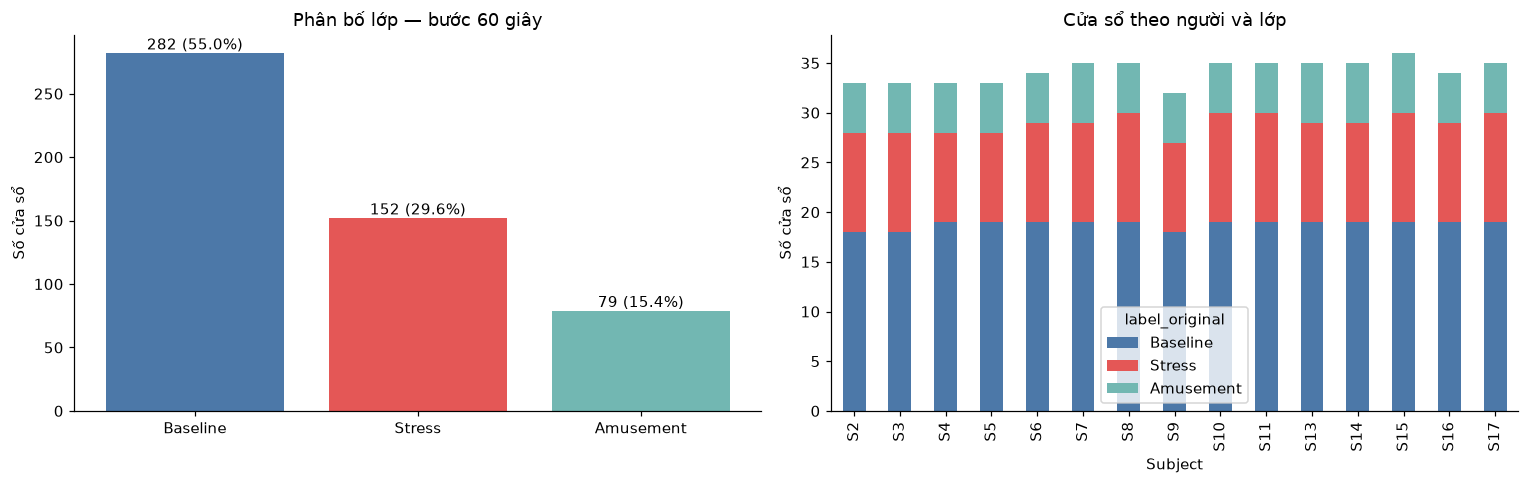

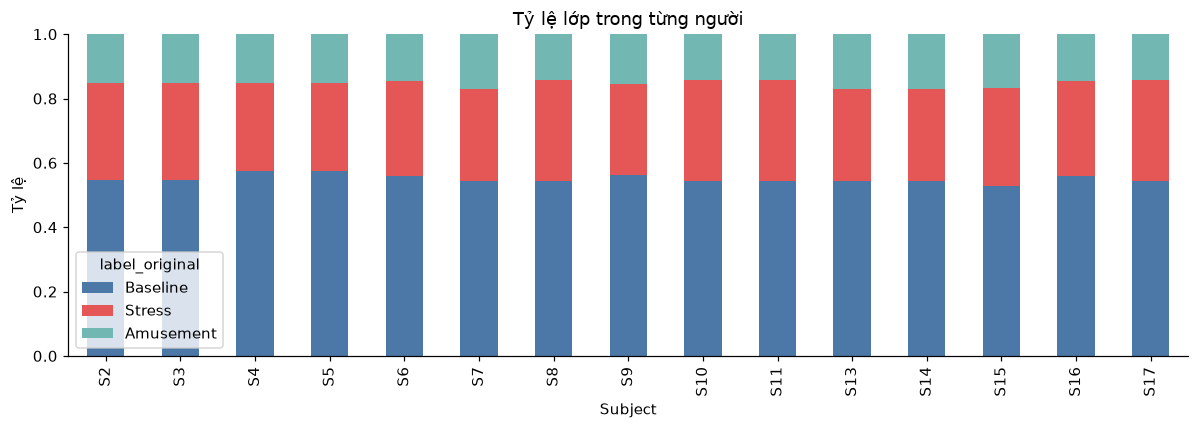

In [41]:
label_counts = df.label_original.value_counts().reindex([1,2,3], fill_value=0)
label_table = pd.DataFrame({'label_original':label_counts.index,
                            'class_name':[LABEL_NAMES[i] for i in label_counts.index],
                            'n_windows':label_counts.values})
label_table['percent'] = 100 * label_table.n_windows / len(df)
subject_label = pd.crosstab(df.subject_id, df.label_original).reindex(index=subject_order, columns=[1,2,3], fill_value=0)
subject_table = subject_label.rename(columns=LABEL_NAMES).copy()
subject_table['total'] = subject_table.sum(axis=1)
subject_table.index.name = 'subject_id'
display(label_table)
display(subject_table)
save_table(label_table, 'label_distribution.csv')
save_table(subject_table, 'windows_by_subject_and_label.csv', index=True)
if (subject_label == 0).any().any():
    warnings.warn('Có subject thiếu ít nhất một lớp; cần ghi rõ khi đánh giá LOSO.')

fig, axes = plt.subplots(1,2,figsize=(14,4.5))
axes[0].bar(label_table.class_name, label_table.n_windows, color=COLORS)
axes[0].set(title='Phân bố lớp — bước 60 giây', ylabel='Số cửa sổ')
for i, row in label_table.iterrows():
    axes[0].text(i, row.n_windows, f'{row.n_windows} ({row.percent:.1f}%)', ha='center', va='bottom')
subject_label.rename(columns=LABEL_NAMES).plot.bar(stacked=True, ax=axes[1], color=COLORS)
axes[1].set(title='Cửa sổ theo người và lớp', xlabel='Subject', ylabel='Số cửa sổ')
save_figure(fig, '01_label_subject_distribution.png')
fig, ax = plt.subplots(figsize=(11,4))
subject_label.div(subject_label.sum(axis=1), axis=0).rename(columns=LABEL_NAMES).plot.bar(stacked=True, ax=ax, color=COLORS)
ax.set(title='Tỷ lệ lớp trong từng người', xlabel='Subject', ylabel='Tỷ lệ', ylim=(0,1))
save_figure(fig, '02_class_proportions_by_subject.png')


## 4. Chất lượng dữ liệu
Kiểm tra NaN, Inf, khóa trùng, cột hằng và cờ chất lượng. Cờ
`finite_only_not_physiological_QA` chỉ cho biết kiểm tra tính hữu hạn,
không xác nhận tín hiệu đạt chất lượng sinh lý. Không tự điền thiếu hoặc xóa mẫu.


In [42]:
values = df[feature_cols].to_numpy(dtype=float)
quality = pd.DataFrame({'feature':feature_cols,
    'nan_count':np.isnan(values).sum(axis=0),
    'inf_count':np.isinf(values).sum(axis=0),
    'n_unique_finite':[df[c].replace([np.inf,-np.inf],np.nan).nunique() for c in feature_cols]})
quality['nan_percent'] = 100 * quality.nan_count / len(df)
quality['constant_or_all_missing'] = quality.n_unique_finite <= 1
duplicates = df[df.duplicated(['subject_id','window_id'], keep=False)].copy()
quality_subject = df[['subject_id']].copy()
quality_subject['n_windows'] = 1
quality_subject['rows_with_nan'] = np.isnan(values).any(axis=1).astype(int)
quality_subject['rows_with_inf'] = np.isinf(values).any(axis=1).astype(int)
quality_subject['duplicate_key_rows'] = df.duplicated(['subject_id','window_id'],keep=False).astype(int)
quality_subject = quality_subject.groupby('subject_id').sum().reindex(subject_order)
flags = df.groupby(['subject_id','quality_flag'],dropna=False).size().rename('n_windows').reset_index()
display(quality)
display(quality_subject)
display(flags)
print('Số dòng thuộc nhóm khóa trùng:', len(duplicates))
save_table(quality, 'feature_quality.csv')
save_table(quality_subject, 'quality_by_subject.csv', index=True)
save_table(flags, 'quality_flags.csv')
save_table(duplicates, 'duplicate_keys.csv')
if len(duplicates) or np.isinf(values).any():
    warnings.warn('Có khóa trùng hoặc Inf: cần điều tra trước khi huấn luyện.')


,feature,nan_count,inf_count,n_unique_finite,nan_percent,constant_or_all_missing
0,ecg_mean,0,0,513,0.0,False
1,ecg_std,0,0,513,0.0,False
2,ecg_min,0,0,504,0.0,False
3,ecg_max,0,0,142,0.0,False
4,ecg_rms,0,0,513,0.0,False
5,ecg_iqr,0,0,500,0.0,False
6,ecg_range,0,0,506,0.0,False
7,eda_mean,0,0,513,0.0,False
8,eda_std,0,0,513,0.0,False
9,eda_min,0,0,508,0.0,False


,n_windows,rows_with_nan,rows_with_inf,duplicate_key_rows
subject_id,,,,
S2,33,0,0,0
S3,33,0,0,0
S4,33,0,0,0
S5,33,0,0,0
S6,34,0,0,0
S7,35,0,0,0
S8,35,0,0,0
S9,32,0,0,0
S10,35,0,0,0


,subject_id,quality_flag,n_windows
0,S10,finite_only_not_physiological_QA,35
1,S11,finite_only_not_physiological_QA,35
2,S13,finite_only_not_physiological_QA,35
3,S14,finite_only_not_physiological_QA,35
4,S15,finite_only_not_physiological_QA,36
5,S16,finite_only_not_physiological_QA,34
6,S17,finite_only_not_physiological_QA,35
7,S2,finite_only_not_physiological_QA,33
8,S3,finite_only_not_physiological_QA,33
9,S4,finite_only_not_physiological_QA,33


Số dòng thuộc nhóm khóa trùng: 0


## 5. Thống kê mô tả, phân bố và điểm cực trị
Biểu đồ dùng giá trị hữu hạn; NaN/Inf vẫn được báo cáo ở mục 4 và bảng gốc
không bị thay đổi. Quy tắc IQR chỉ đánh dấu điểm xa phân bố chung để xem xét;
khác biệt giữa người/trạng thái có thể hợp lệ, không tự loại những điểm này.


,count,mean,std,min,25%,50%,75%,max
ecg_mean,513.0,0.001097,0.000470,-0.001972,0.000878,0.001125,0.001372,0.002325
ecg_std,513.0,0.262983,0.064003,0.109710,0.230189,0.267879,0.299357,0.476084
ecg_min,513.0,-0.633059,0.246622,-1.500000,-0.775726,-0.573807,-0.442703,-0.213089
ecg_max,513.0,1.426927,0.189003,0.769455,1.496658,1.499222,1.499451,1.499954
ecg_rms,513.0,0.262986,0.064002,0.109718,0.230194,0.267881,0.299361,0.476085
ecg_iqr,513.0,0.136166,0.068280,0.047333,0.092789,0.130245,0.156006,0.520947
ecg_range,513.0,2.059986,0.339442,1.043427,1.920593,2.035950,2.255585,2.999451
eda_mean,513.0,4.589126,3.463852,0.635997,1.975580,3.708698,6.308028,19.969665
eda_std,513.0,0.051785,0.085745,0.007825,0.013666,0.018298,0.045203,1.129439
eda_min,513.0,4.345533,3.429493,0.000000,1.697922,3.504944,6.077194,19.680405


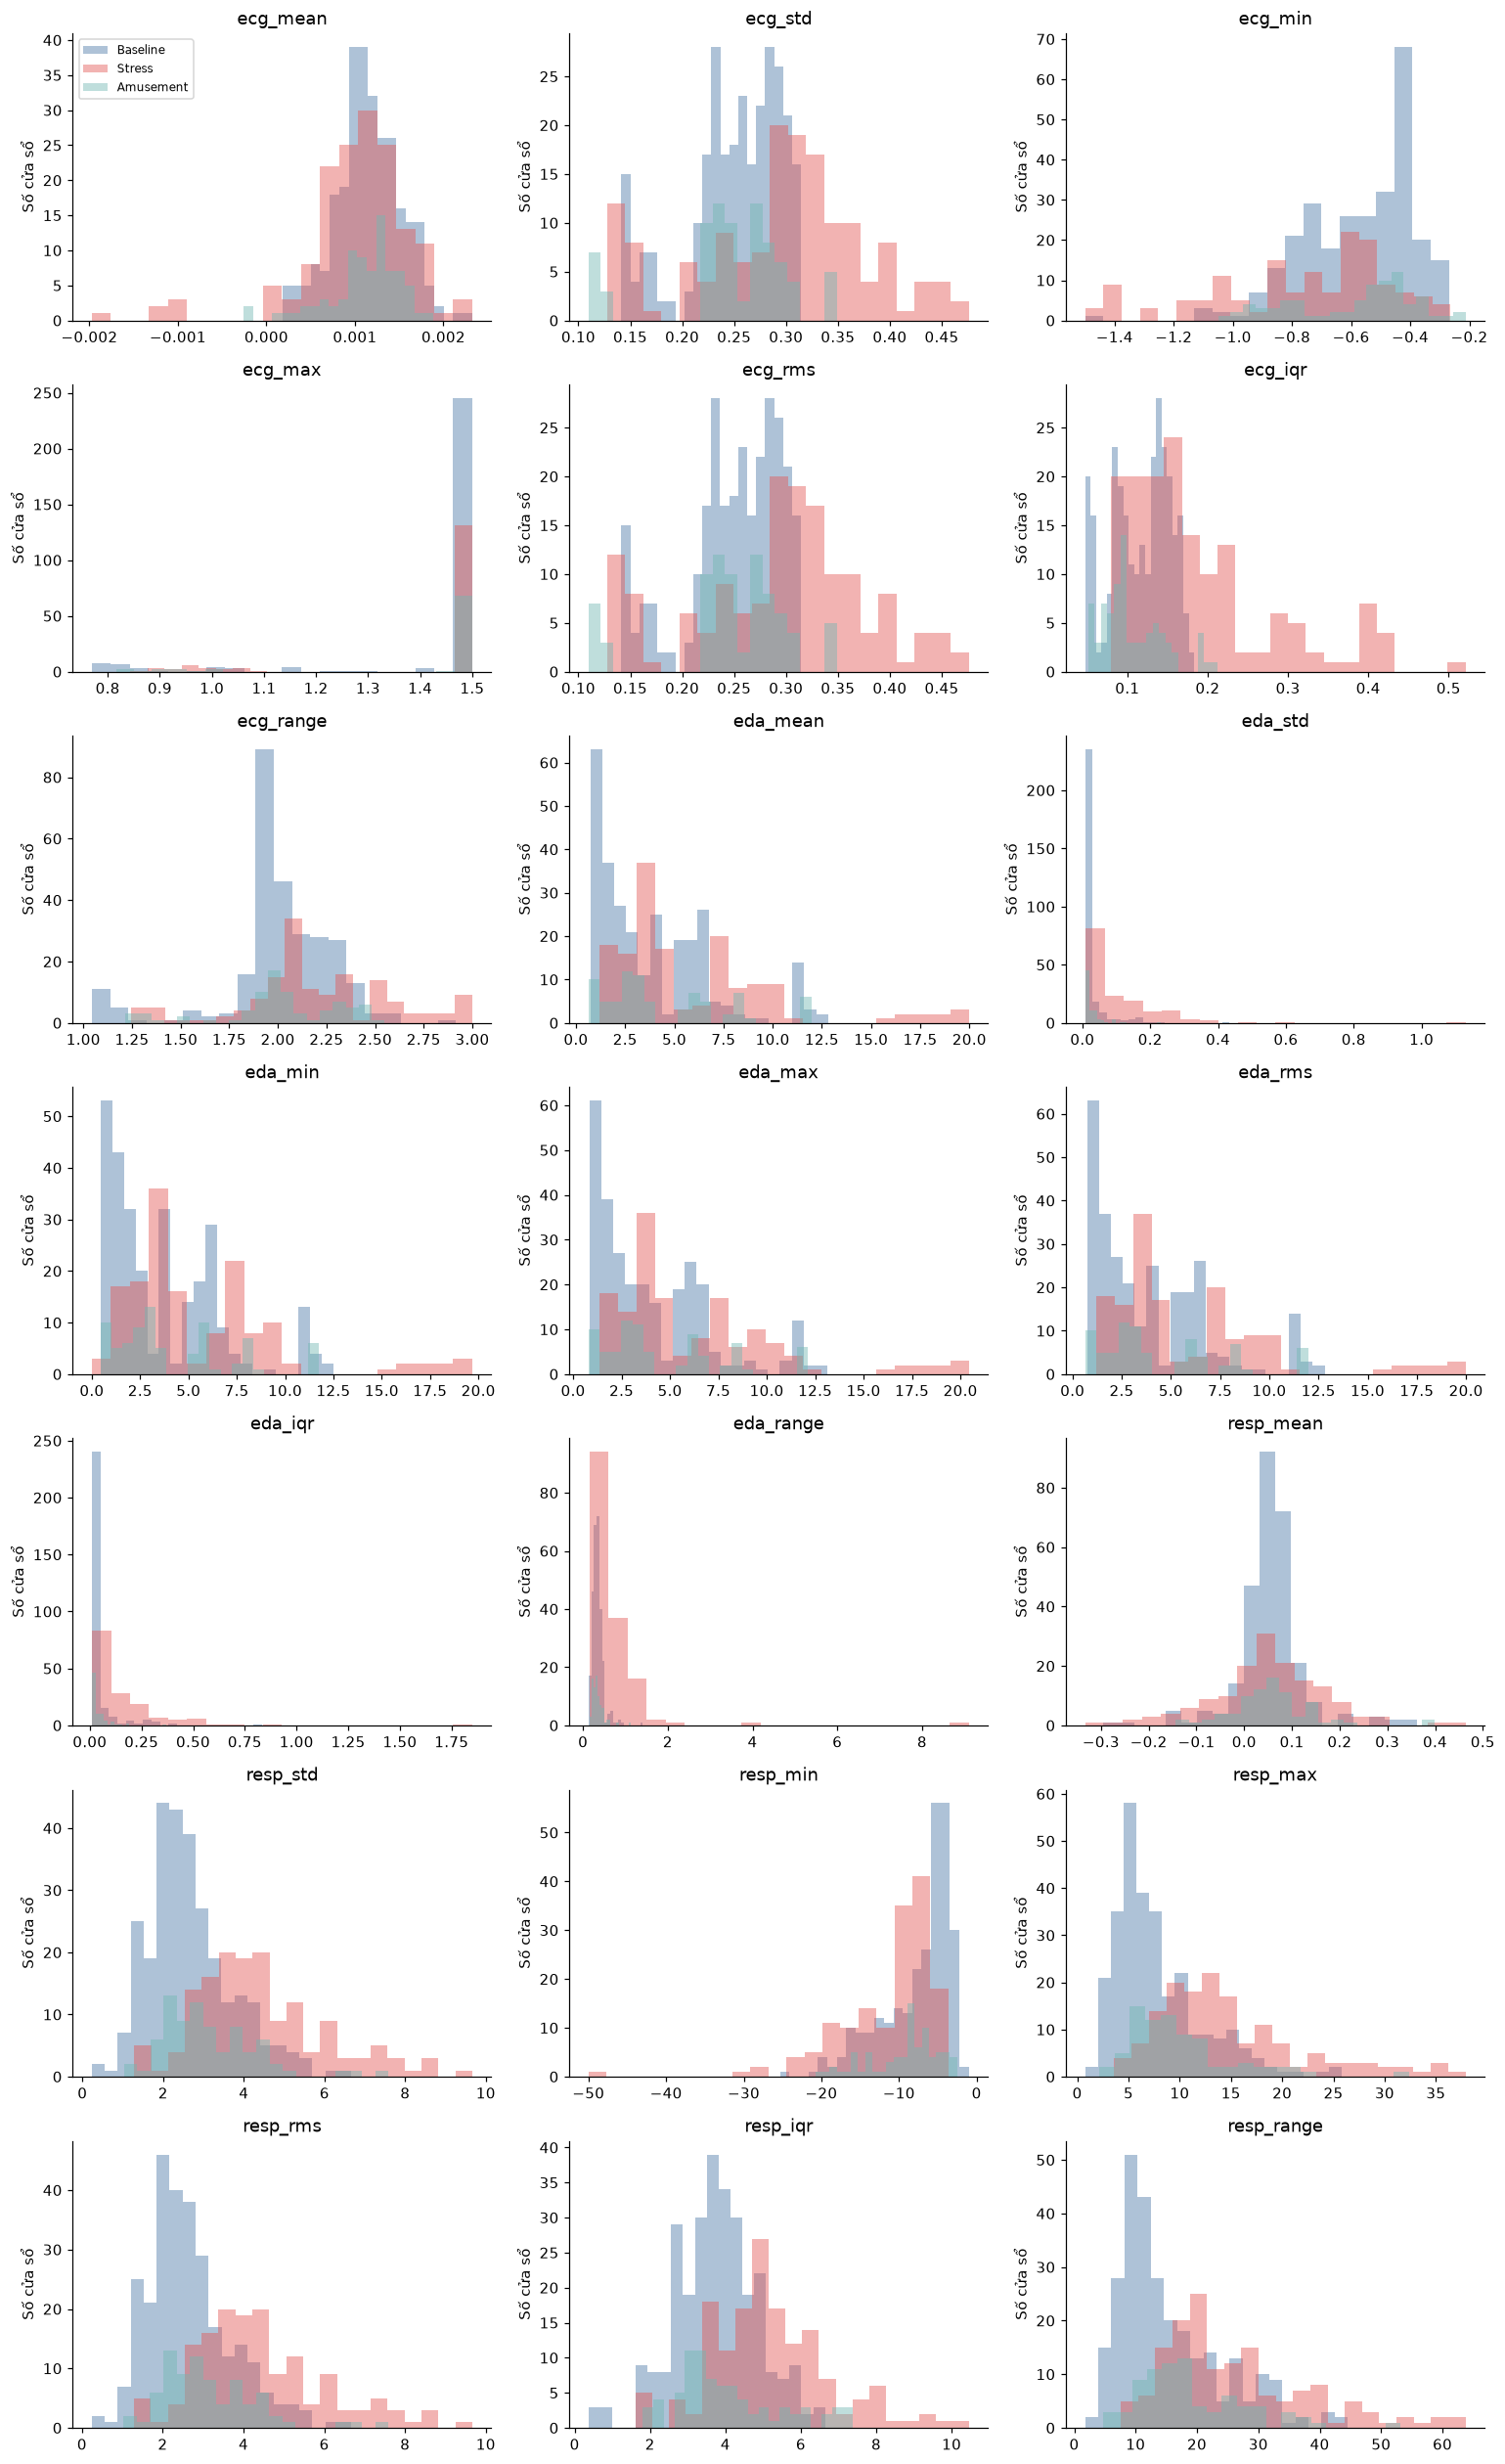

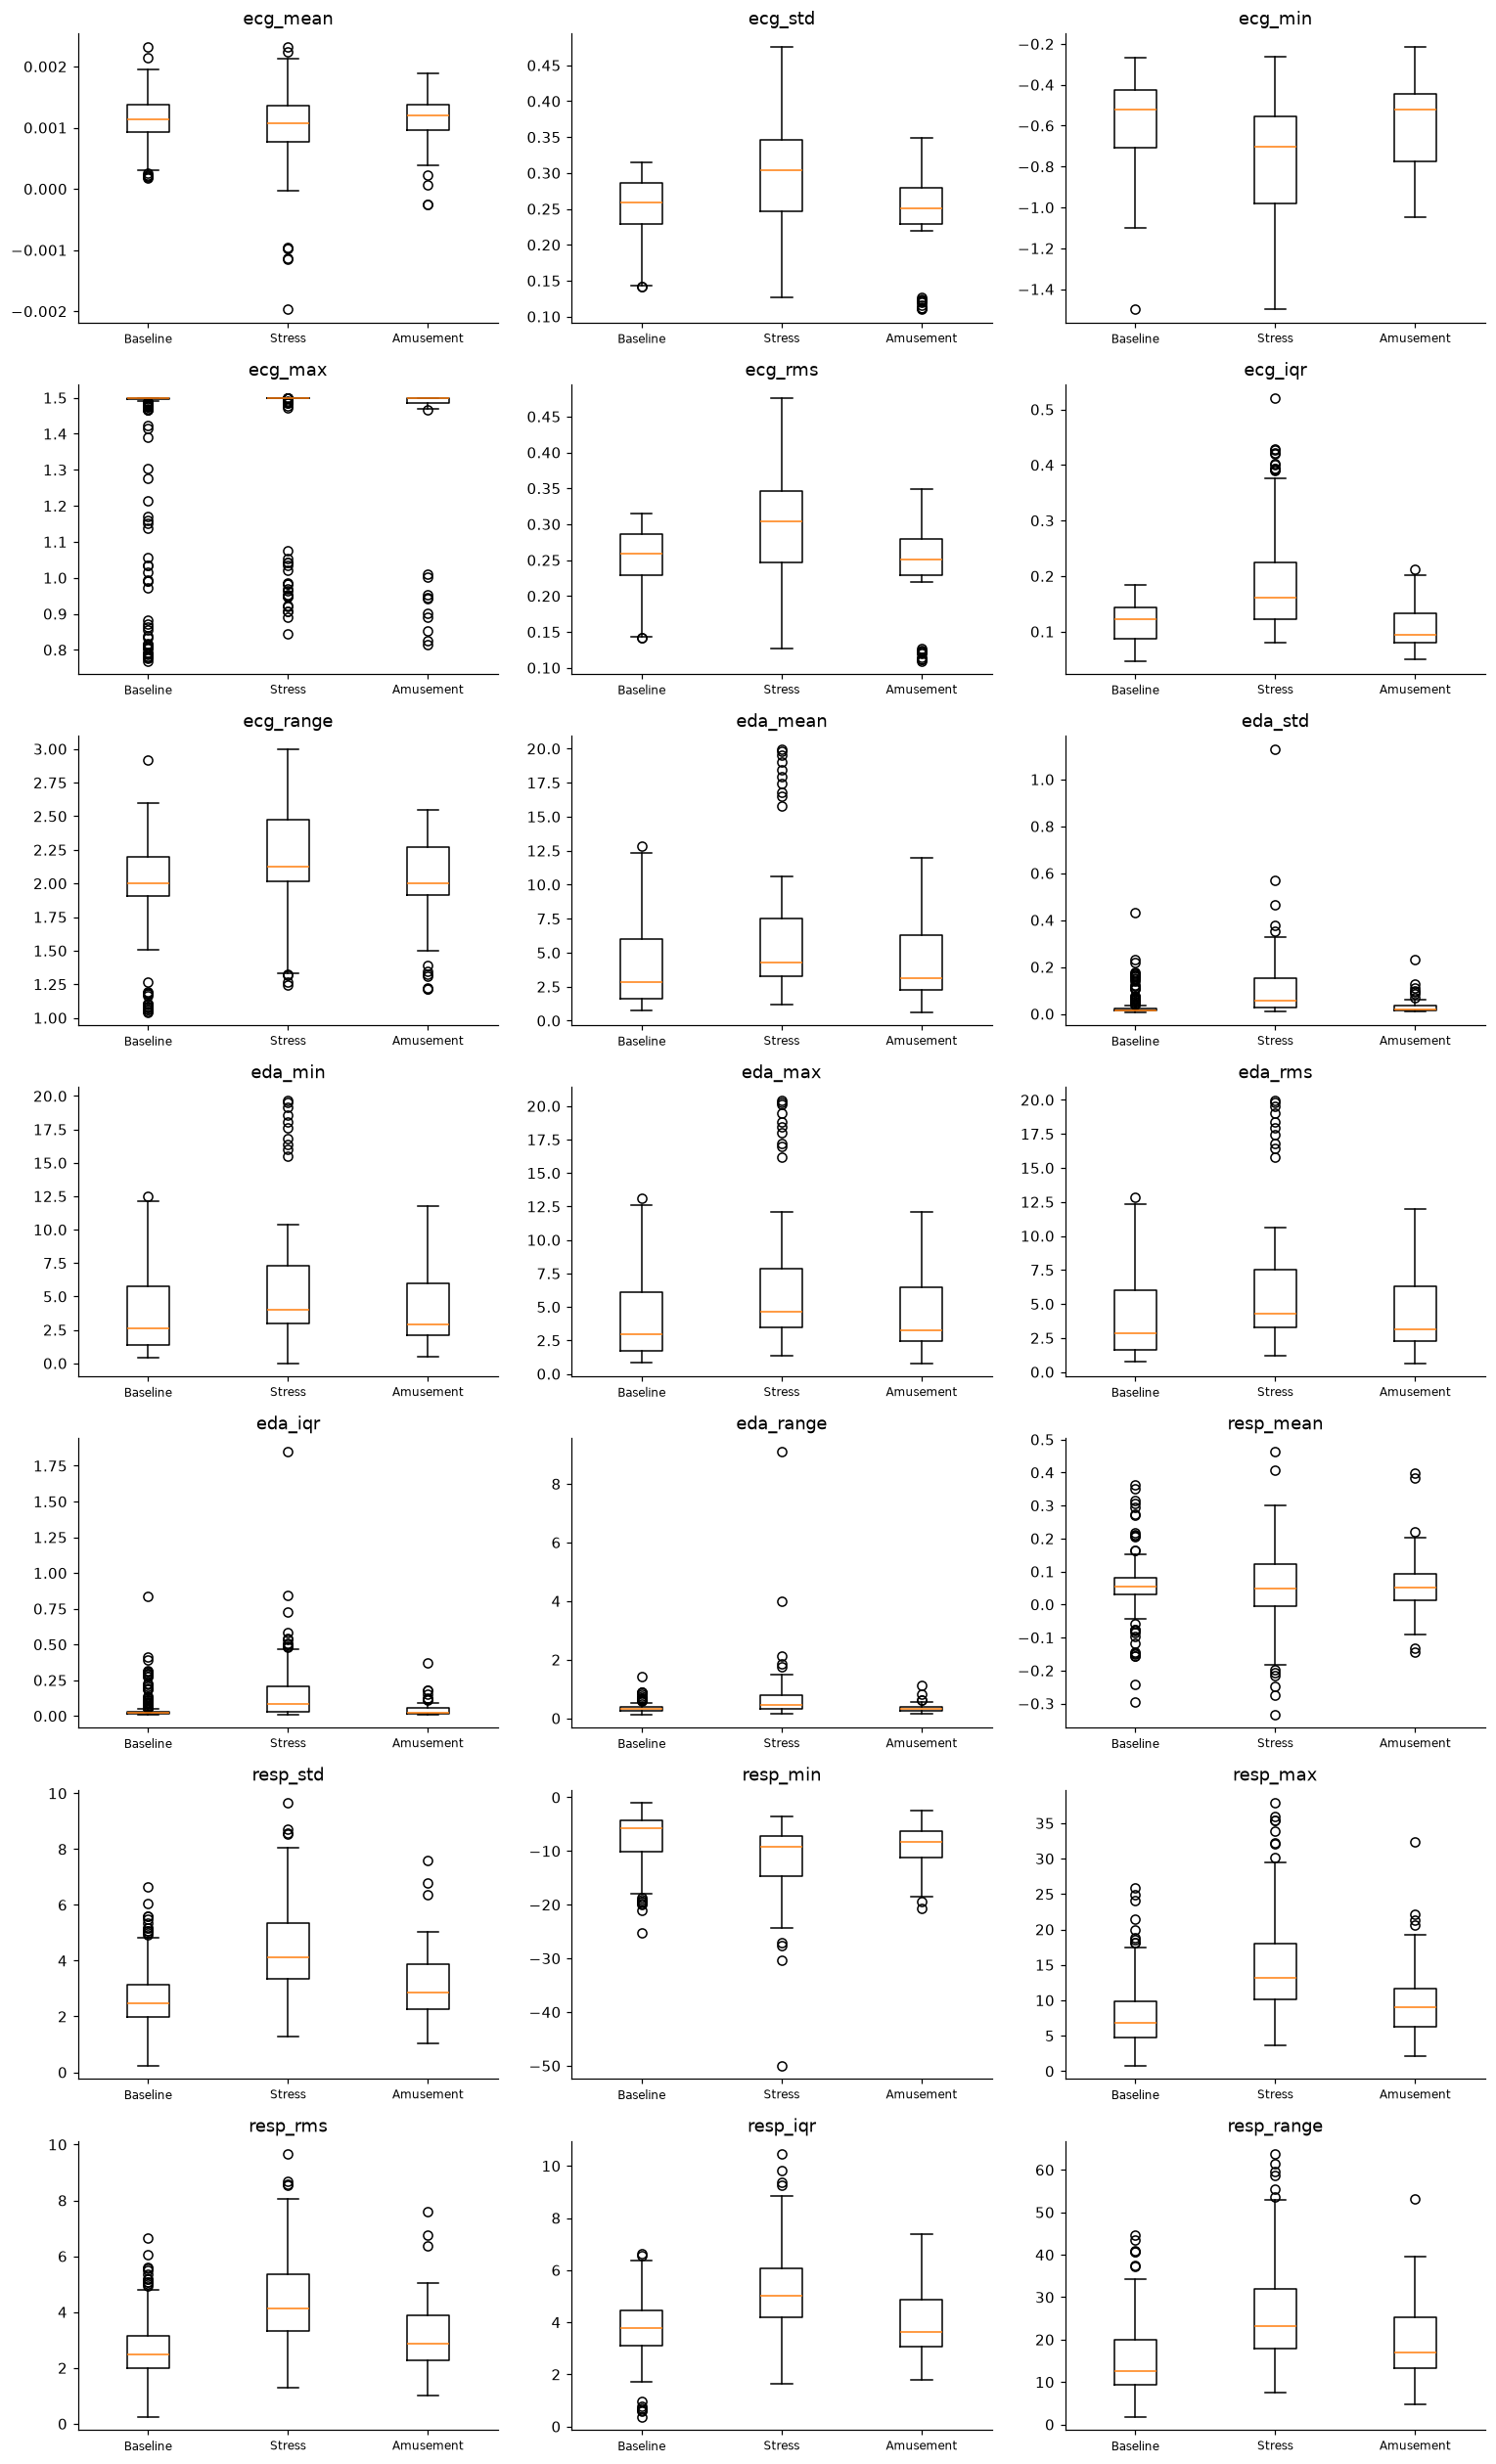

,feature,iqr,flagged_count,finite_count,flagged_percent
3,ecg_max,0.002792,116,513,22.612086
8,eda_std,0.031536,83,513,16.179337
12,eda_iqr,0.047684,78,513,15.204678
14,resp_mean,0.070080,62,513,12.085770
13,eda_range,0.175476,56,513,10.916179
6,ecg_range,0.334991,49,513,9.551657
5,ecg_iqr,0.063217,30,513,5.847953
1,ecg_std,0.069168,22,513,4.288499
4,ecg_rms,0.069167,22,513,4.288499
19,resp_iqr,1.641846,21,513,4.093567


In [43]:
finite = df[feature_cols].replace([np.inf,-np.inf],np.nan)
description = finite.describe().T
save_table(description, 'feature_descriptive_statistics.csv', index=True)
display(description)
by_label = finite.assign(label_original=df.label_original).groupby('label_original').agg(['count','mean','std','median'])
by_label.columns = ['__'.join(col) for col in by_label.columns]
save_table(by_label, 'feature_statistics_by_label.csv', index=True)

fig, axes = plt.subplots(7,3,figsize=(14,23))
for ax, col in zip(axes.flat, feature_cols):
    for label, color in zip([1,2,3], COLORS):
        x = finite.loc[df.label_original == label,col].dropna()
        if len(x):
            ax.hist(x, bins=20, alpha=.45, color=color, label=LABEL_NAMES[label])
    ax.set(title=col, ylabel='Số cửa sổ')
axes.flat[0].legend(fontsize=8)
save_figure(fig, '03_histograms_by_label.png')

fig, axes = plt.subplots(7,3,figsize=(14,23))
for ax, col in zip(axes.flat, feature_cols):
    groups = [finite.loc[df.label_original == k,col].dropna().to_numpy() for k in [1,2,3]]
    ax.boxplot(groups, tick_labels=list(LABEL_NAMES.values()), showfliers=True)
    ax.set_title(col)
    ax.tick_params(axis='x',labelsize=8)
save_figure(fig, '04_boxplots_by_label.png')

q1, q3 = finite.quantile(.25), finite.quantile(.75)
iqr = q3 - q1
outlier_mask = finite.lt(q1 - 1.5*iqr) | finite.gt(q3 + 1.5*iqr)
outlier_table = pd.DataFrame({'feature':feature_cols, 'iqr':iqr.values,
    'flagged_count':outlier_mask.sum().values, 'finite_count':finite.notna().sum().values})
outlier_table['flagged_percent'] = 100*outlier_table.flagged_count/outlier_table.finite_count.replace(0,np.nan)
display(outlier_table.sort_values('flagged_count',ascending=False))
save_table(outlier_table, 'iqr_review_flags.csv')


## 6. Tương quan và khác biệt giữa người
Pearson mô tả liên hệ tuyến tính giữa đặc trưng, không chứng minh quan hệ
nhân quả. Không chọn/xóa cột dựa vào toàn bảng rồi báo kết quả test như một
đánh giá hoàn toàn độc lập; nếu chọn đặc trưng cho mô hình, thực hiện trong fold train.


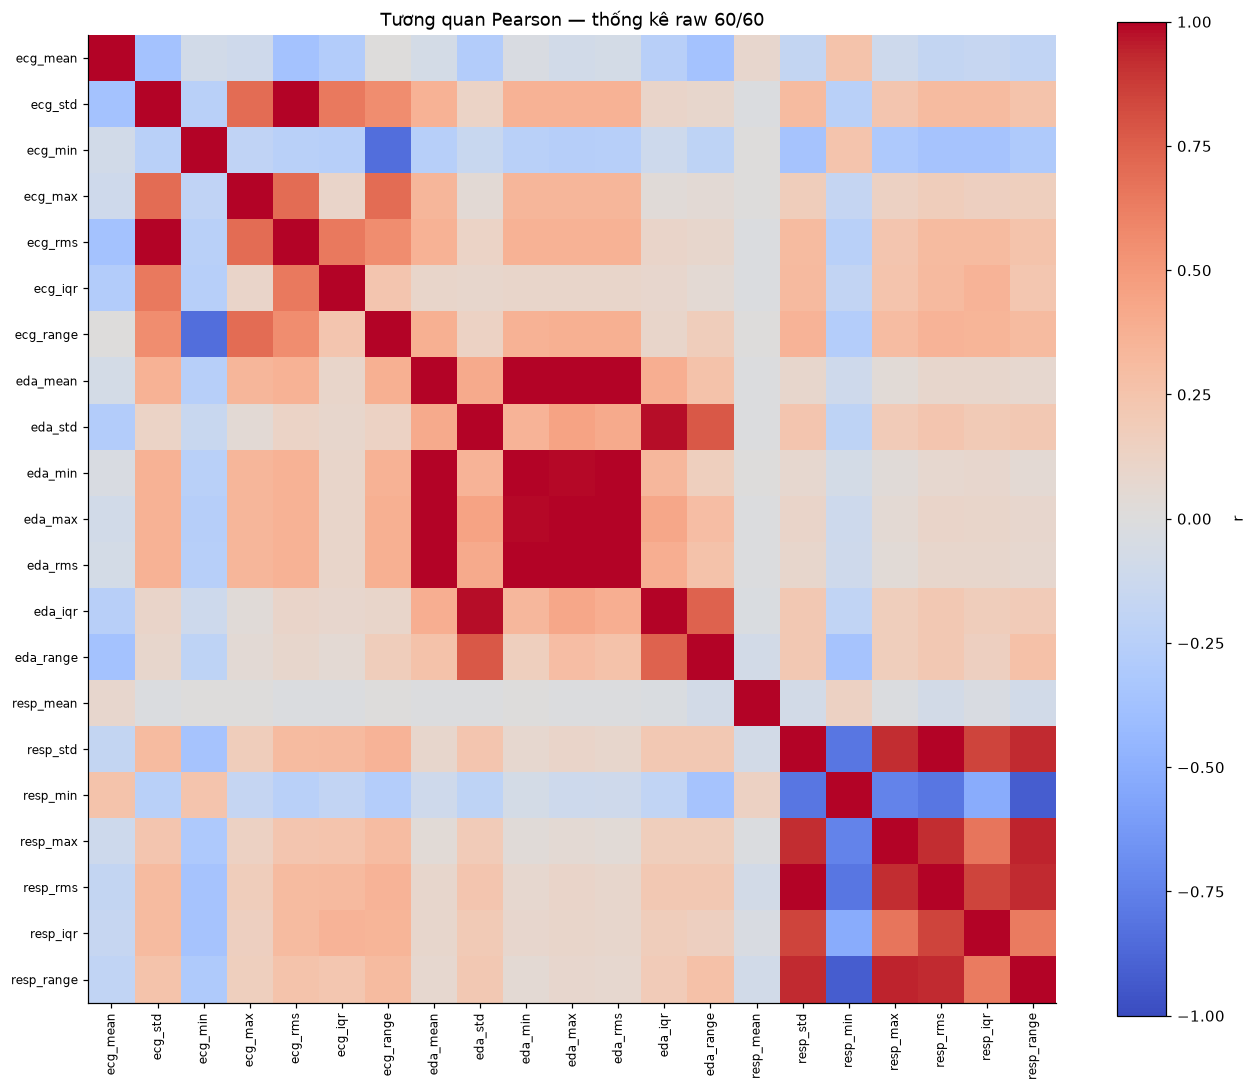

,feature_a,feature_b,pearson_r
0,ecg_std,ecg_rms,1.000000
1,eda_mean,eda_min,0.993950
2,eda_mean,eda_max,0.998779
3,eda_mean,eda_rms,1.000000
4,eda_std,eda_iqr,0.981839
5,eda_min,eda_max,0.990697
6,eda_min,eda_rms,0.993897
7,eda_max,eda_rms,0.998810
8,resp_std,resp_rms,0.999998


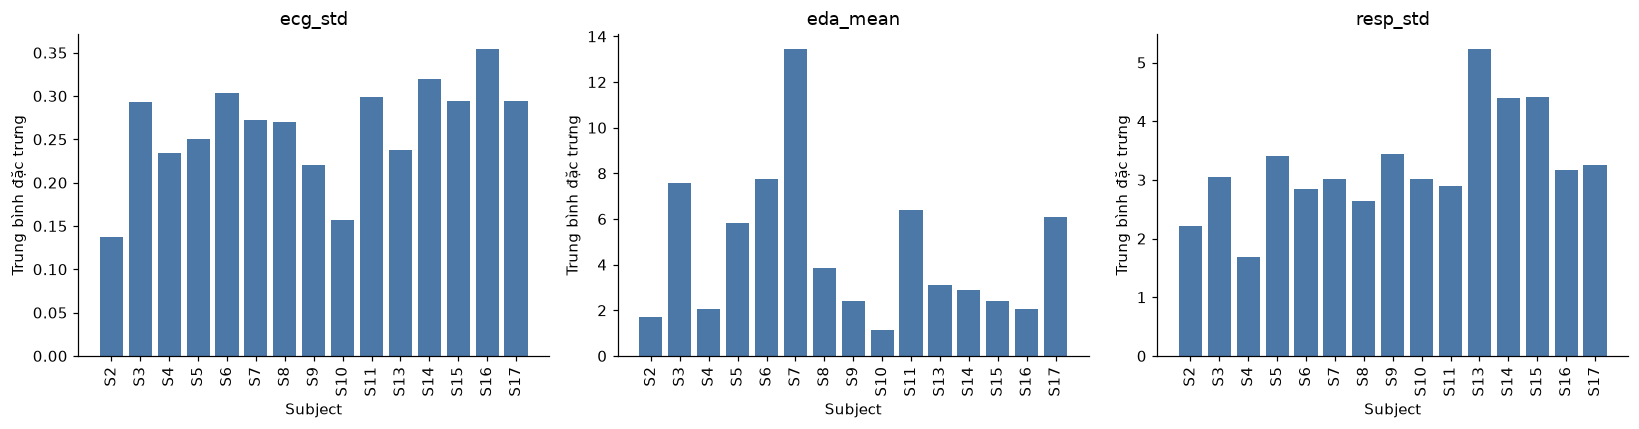

In [44]:
corr = finite.corr(method='pearson')
save_table(corr, 'pearson_correlation.csv', index=True)
fig, ax = plt.subplots(figsize=(12,10))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(feature_cols)), feature_cols, fontsize=8)
ax.set_title('Tương quan Pearson — thống kê raw 60/60')
fig.colorbar(im, ax=ax, label='r')
save_figure(fig, '05_pearson_heatmap.png')
pairs = [{'feature_a':a,'feature_b':b,'pearson_r':corr.loc[a,b]}
         for i,a in enumerate(feature_cols) for b in feature_cols[i+1:]
         if pd.notna(corr.loc[a,b]) and abs(corr.loc[a,b]) >= .95]
high_corr = pd.DataFrame(pairs, columns=['feature_a','feature_b','pearson_r'])
display(high_corr)
save_table(high_corr, 'high_correlation_pairs.csv')
subject_means = finite.assign(subject_id=df.subject_id).groupby('subject_id').mean().reindex(subject_order)
save_table(subject_means, 'mean_features_by_subject.csv', index=True)
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, col in zip(axes, ['ecg_std','eda_mean','resp_std']):
    ax.bar(subject_order, subject_means[col], color='#4c78a8')
    ax.set(title=col, xlabel='Subject', ylabel='Trung bình đặc trưng')
    ax.tick_params(axis='x',rotation=90)
save_figure(fig, '06_subject_differences.png')


## 7. Khảo sát tín hiệu thô 
Phần bảng feature phía trên không thay thế khảo sát tín hiệu thô.Chỉ mở PKL từ bộ WESAD tin cậy vì pickle có thể thực thi mã.
Đọc tuần tự từng người để giảm RAM; đếm nhãn gốc, kiểm tra NaN/Inf ở ECG/EDA/ACC
ngực và vẽ một đoạn 10 giây đồng nhất cho mỗi trạng thái của subject minh họa.
Phần này không tạo bảng feature mới


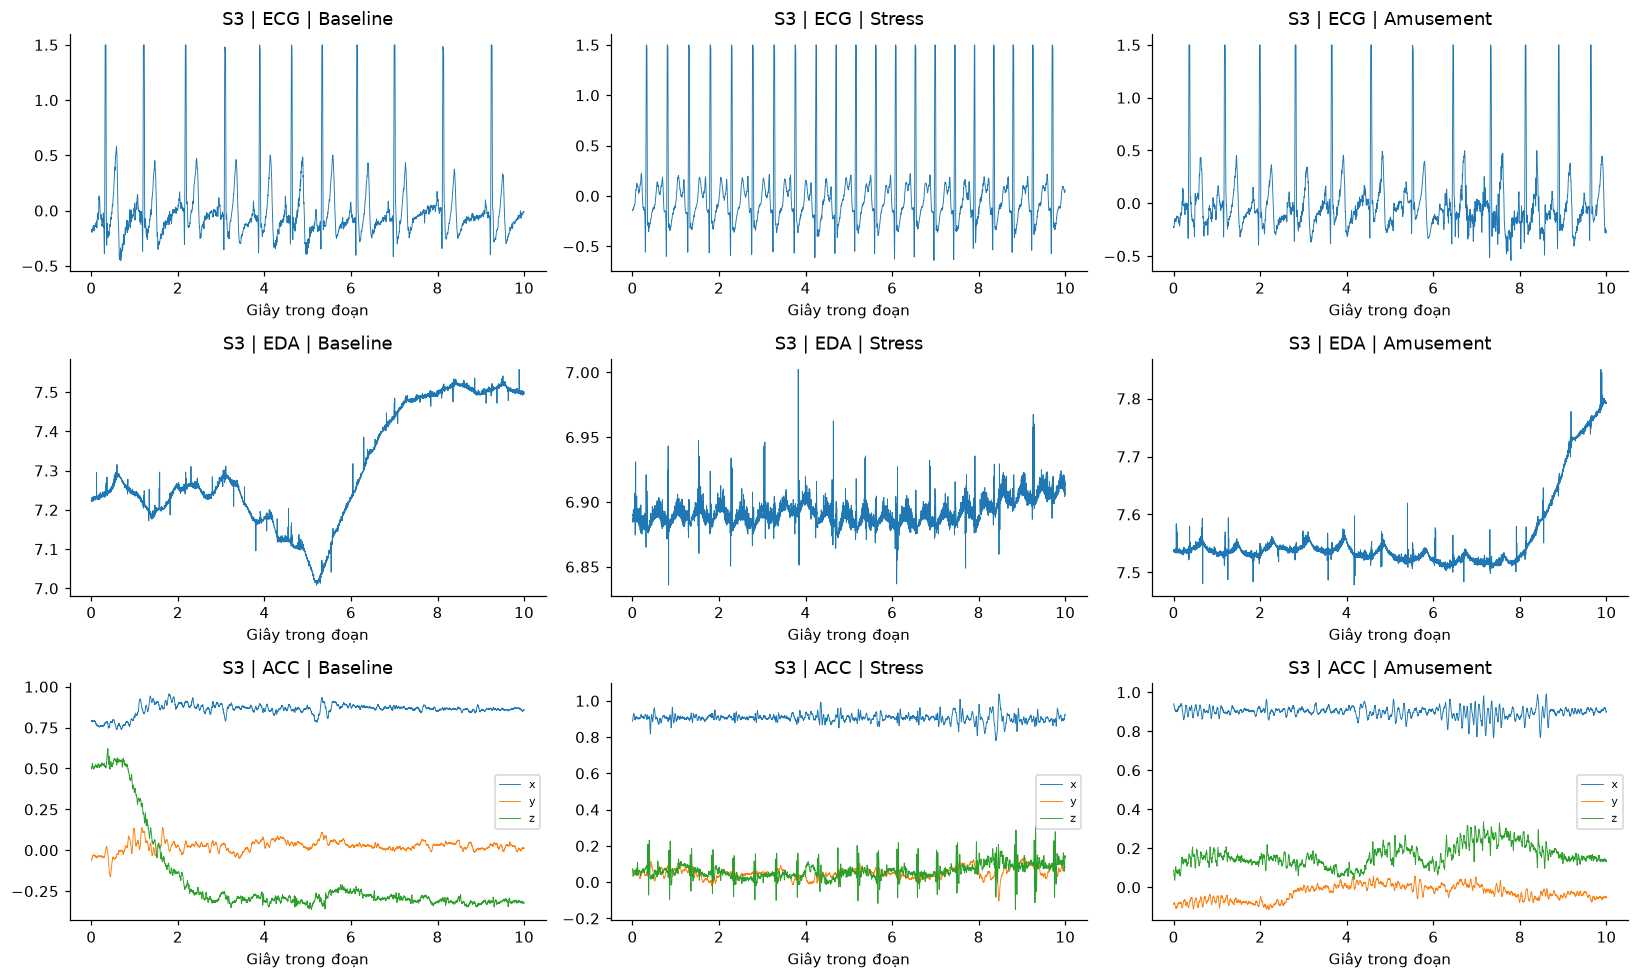

,subject_id,label,n_samples,seconds_at_700hz
0,S2,0,2142701,3061.001429
1,S2,1,800800,1144.000000
2,S2,2,430500,615.000000
3,S2,3,253400,362.000000
4,S2,4,537599,767.998571
...,...,...,...,...
114,S17,3,260400,372.000000
115,S17,4,511700,731.000000
116,S17,5,40600,58.000000
117,S17,6,41299,58.998571


,subject_id,sensor,shape,nan_values,inf_values,length_matches_labels
0,S2,ECG,"(4255300, 1)",0,0,True
1,S2,EDA,"(4255300, 1)",0,0,True
2,S2,ACC,"(4255300, 3)",0,0,True
3,S3,ECG,"(4545100, 1)",0,0,True
4,S3,EDA,"(4545100, 1)",0,0,True
5,S3,ACC,"(4545100, 3)",0,0,True
6,S4,ECG,"(4496100, 1)",0,0,True
7,S4,EDA,"(4496100, 1)",0,0,True
8,S4,ACC,"(4496100, 3)",0,0,True
9,S5,ECG,"(4380600, 1)",0,0,True


In [45]:
RUN_RAW_EDA = True
RAW_ROOT = PROJECT_ROOT / '../data/raw/WESAD/WESAD'
RAW_SUBJECTS = EXPECTED_SUBJECTS
ILLUSTRATION_SUBJECT = 'S3'

if RUN_RAW_EDA:
    import pickle
    import gc
    raw_labels, raw_quality = [], []
    for subject in RAW_SUBJECTS:
        path = RAW_ROOT / subject / f'{subject}.pkl'
        if not path.is_file():
            warnings.warn(f'Bỏ qua file không có: {path}')
            continue
        with path.open('rb') as f:
            raw = pickle.load(f, encoding='latin1')
        labels = np.asarray(raw['label']).reshape(-1)
        unique, counts = np.unique(labels, return_counts=True)
        raw_labels.extend({'subject_id':subject,'label':int(k),'n_samples':int(v),
                           'seconds_at_700hz':int(v)/700} for k,v in zip(unique,counts))
        chest = raw['signal']['chest']
        for sensor in ['ECG','EDA','ACC']:
            x = np.asarray(chest[sensor])
            raw_quality.append({'subject_id':subject,'sensor':sensor,'shape':str(x.shape),
                'nan_values':int(np.isnan(x).sum()),'inf_values':int(np.isinf(x).sum()),
                'length_matches_labels':len(x)==len(labels)})
        if subject == ILLUSTRATION_SUBJECT:
            n = 10*700
            fig, axes = plt.subplots(3,3,figsize=(15,9))
            for j, label in enumerate([1,2,3]):
                mask = labels == label
                edges = np.diff(np.r_[False,mask,False].astype(int))
                starts, ends = np.flatnonzero(edges==1), np.flatnonzero(edges==-1)
                starts = starts[(ends-starts)>=n]
                for i,sensor in enumerate(['ECG','EDA','ACC']):
                    ax = axes[i,j]
                    ax.set_title(f'{subject} | {sensor} | {LABEL_NAMES[label]}')
                    ax.set_xlabel('Giây trong đoạn')
                    if not len(starts):
                        ax.text(.5,.5,'Không có đoạn đủ 10 giây',ha='center',transform=ax.transAxes)
                        continue
                    start = int(starts[0])
                    segment = np.asarray(chest[sensor])[start:start+n]
                    ax.plot(np.arange(len(segment))/700, segment, linewidth=.6)
                    if sensor == 'ACC':
                        ax.legend(['x','y','z'],fontsize=7)
            save_figure(fig, f'07_raw_signals_{subject}.png')
        del raw, chest
        gc.collect()
    if not raw_labels:
        raise FileNotFoundError('Không đọc được PKL nào; kiểm tra RAW_ROOT.')
    raw_label_table = pd.DataFrame(raw_labels)
    raw_quality_table = pd.DataFrame(raw_quality)
    display(raw_label_table)
    display(raw_quality_table)
    save_table(raw_label_table, 'raw_label_distribution.csv')
    save_table(raw_quality_table, 'raw_signal_quality.csv')
else:
    print('Chưa chạy khảo sát tín hiệu thô. Bật RUN_RAW_EDA khi có PKL và cần bổ sung G1.')


## 8. Tóm tắt tự động và lưu thông tin lần chạy


In [46]:
nonzero = label_counts[label_counts>0]
ratio = float(nonzero.max()/nonzero.min()) if len(nonzero)==3 else None
summary = {
    'created_at_utc':datetime.now(timezone.utc).isoformat(),
    'input_file':str(FEATURE_PATH),
    'input_sha256':hashlib.sha256(FEATURE_PATH.read_bytes()).hexdigest(),
    'scope':'chest raw statistics; window 60s; step 60s; homogeneous labels',
    'processing_metadata_verified':processing is not None,
    'processing':processing,
    'n_windows':len(df),'n_subjects':len(subject_order),'n_features':len(feature_cols),
    'subjects':subject_order, 'missing_subjects':missing_subjects,
    'label_counts':{str(k):int(v) for k,v in label_counts.items()},
    'largest_smallest_class_ratio':ratio,
    'nan_feature_values':int(np.isnan(values).sum()),
    'inf_feature_values':int(np.isinf(values).sum()),
    'duplicate_key_rows':len(duplicates),
    'constant_or_all_missing_features':quality.loc[quality.constant_or_all_missing,'feature'].tolist(),
    'raw_eda_enabled':RUN_RAW_EDA,
    'interpretation_limit':'Exploratory full-table analysis; no model performance or physiological QA claim.'
}
(TABLE_DIR / 'eda_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'Có {len(df)} cửa sổ từ {len(subject_order)} người, với {len(feature_cols)} đặc trưng.')
print('Số mẫu Baseline/Stress/Amusement:', label_counts.tolist())
print('Tỷ lệ lớp lớn nhất / nhỏ nhất:', round(ratio,2) if ratio is not None else 'Thiếu ít nhất một lớp')
print('NaN:', summary['nan_feature_values'], '| Inf:', summary['inf_feature_values'], '| Dòng khóa trùng:',len(duplicates))



Có 513 cửa sổ từ 15 người, với 21 đặc trưng.
Số mẫu Baseline/Stress/Amusement: [282, 152, 79]
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.57
NaN: 0 | Inf: 0 | Dòng khóa trùng: 0


## 9. Nhận xét kết quả khám phá dữ liệu

### 9.1. Phạm vi dữ liệu

Bảng đặc trưng được khảo sát gồm 513 cửa sổ của 15 người tham gia,
với 21 đặc trưng thống kê từ ba tín hiệu ngực: ECG, EDA và Resp.
Mỗi cửa sổ dài 60 giây; các mốc thời gian phù hợp với lưới bước
trượt 60 giây.

Các đặc trưng gồm mean, std, min, max, RMS, IQR và range của từng
tín hiệu. Đây là các thống kê trên tín hiệu thô, chưa phải bộ đặc
trưng sinh lý chuyên biệt như HRV hoặc SCR.

Dữ liệu đầu vào chưa có config.json đi kèm. Vì vậy, chưa xác minh
được quy tắc gán nhãn homogeneous từ metadata của lần trích xuất.
Đây là hạn chế về khả năng truy vết cấu hình cần được ghi nhận.

### 9.2. Phân bố lớp và người tham gia

Baseline có 282 cửa sổ, chiếm 54,97%; Stress có 152 cửa sổ,
chiếm 29,63%; Amusement có 79 cửa sổ, chiếm 15,40%.
Lớp lớn nhất có số cửa sổ gấp khoảng 3,57 lần lớp nhỏ nhất,
cho thấy dữ liệu mất cân bằng lớp.

Cả 15 người đều có đủ ba lớp. Số cửa sổ của mỗi người dao động
từ 32 đến 36, tương đối đồng đều giữa các người tham gia.

Khi đánh giá mô hình, sử dụng Macro-F1 và Balanced Accuracy để
phản ánh kết quả trên các lớp, đồng thời báo cáo kết quả theo
từng người thay vì chỉ dựa vào Accuracy chung.

### 9.3. Chất lượng bảng đặc trưng

Không phát hiện NaN, Inf hoặc khóa trùng theo cặp subject_id và
window_id. Không có đặc trưng hằng hoặc thiếu toàn bộ giá trị.
Các cửa sổ đều vượt qua kiểm tra độ dài 60 giây.

Tuy nhiên, quality_flag có giá trị
finite_only_not_physiological_QA. Kết quả này không chứng minh
tín hiệu đã đạt chất lượng sinh lý hoặc hoàn toàn không có nhiễu.

### 9.4. Phân bố đặc trưng và điểm cực trị

Quy tắc IQR đánh dấu nhiều điểm cần xem xét ở một số đặc trưng.
Cụ thể, ecg_max có 116 cửa sổ bị đánh dấu, chiếm 22,61%;
eda_std có 83 cửa sổ, chiếm 16,18%; eda_iqr có 78 cửa sổ,
chiếm 15,20%.

Các điểm này chưa được xem là dữ liệu lỗi. Chúng có thể phản ánh
khác biệt giữa người tham gia, trạng thái hoặc vấn đề của tín hiệu.
Trong giai đoạn EDA, giữ nguyên các mẫu và ghi nhận để kiểm tra
nguồn tín hiệu khi cần thiết.

Các đặc trưng có thang giá trị khác nhau. Khi sử dụng KNN và SVM,
cần chuẩn hóa trong pipeline, với tham số chuẩn hóa chỉ được học
từ tập train của từng fold.

### 9.5. Tương quan giữa các đặc trưng

Một số cặp đặc trưng có tương quan Pearson rất cao:
ecg_std và ecg_rms có r xấp xỉ 1;
eda_mean và eda_rms có r xấp xỉ 1;
resp_std và resp_rms có r xấp xỉ 0,999998.

Các đặc trưng này có thể mang thông tin gần nhau. Tuy nhiên,
chưa tự động loại cột chỉ dựa trên tương quan của toàn bộ dữ liệu.
Nếu thực hiện chọn đặc trưng cho mô hình, bước này phải được
thực hiện bên trong tập train của từng fold.

### 9.6. Khảo sát tín hiệu thô

Đã khảo sát nhãn trong dữ liệu thô của đủ 15 người và kiểm tra
ba tín hiệu ngực ECG, EDA và ACC. Tổng cộng có 45 cặp
người–tín hiệu được kiểm tra; không phát hiện NaN hoặc Inf,
và độ dài của các tín hiệu đều khớp với chuỗi nhãn tương ứng.

Đã vẽ các đoạn tín hiệu dài 10 giây của người S3 cho ba trạng thái
Baseline, Stress và Amusement. Hình này phục vụ quan sát ban đầu;
một đoạn minh họa chưa đại diện cho toàn bộ tín hiệu hoặc tất cả
người tham gia.

Dữ liệu thô chứa các nhãn ngoài 1, 2 và 3. Các nhãn này được
thống kê để mô tả dữ liệu, nhưng không đưa vào bài toán ba lớp
hiện tại và không tự ánh xạ thành non-stress.

### 9.7. Định hướng huấn luyện và thực nghiệm tiếp theo

Sử dụng 21 cột đặc trưng làm đầu vào X. Không đưa subject_id,
window_id, start_s, end_s, quality_flag hoặc các cột nhãn vào X.

Đánh giá theo LOSO: mỗi lượt giữ một người làm test và dùng
những người còn lại làm train. Các bước điền thiếu, chuẩn hóa,
chọn đặc trưng và cân bằng lớp phải được fit trong phần train
của từng fold. Tuning sử dụng các nhóm người trong tập train,
không sử dụng người đang được giữ làm test.

Đối với bài toán nhị phân, Stress là lớp 1; Baseline và Amusement
được gộp thành Non-stress là lớp 0.

Báo cáo hiện tại chỉ sử dụng bước trượt 60 giây. Bước trượt
5 giây được dành cho thực nghiệm và báo cáo tiếp theo.
Khi so sánh hai bước trượt, cần giữ cố định các yếu tố khác.
Nếu đồng thời thay đổi quy tắc nhãn từ homogeneous sang
majority ≥90%, phải ghi rõ kết quả phản ánh cả hai thay đổi.

Kết quả EDA hiện tại chưa phải bằng chứng về hiệu năng hoặc
khả năng khái quát của mô hình KNN/SVM.

## 10. Bàn giao hiện tại và kế hoạch báo cáo sau

**Bàn giao hiện tại:** notebook đã Run All, bảng tại `reports/tables/eda_step60/`,
hình tại `reports/figures/eda_step60/`, nhận xét dựa trên số liệu thật.
Giữ CSV feature lớn theo cách chia sẻ dữ liệu của nhóm; không cần đưa PKL lên Git.
Không coi EDA đã xong là hoàn tất huấn luyện KNN/SVM.

**Báo cáo lần sau:** trích xuất riêng bộ bước 5 giây và chạy EDA tương ứng;
so sánh số cửa sổ, tỷ lệ lớp, chất lượng, thời gian xử lý và kết quả LOSO cùng subject.
Muốn đo riêng tác động của bước trượt, giữ nguyên cảm biến, đặc trưng,
độ dài cửa sổ, quy tắc nhãn, tiền xử lý và giao thức đánh giá. Nếu bộ 5 giây
dùng majority ≥90% còn bộ hiện tại dùng homogeneous, phải ghi rõ đây là
so sánh hai cấu hình với cả bước trượt và quy tắc nhãn cùng thay đổi.
